# 08 - Industry Exposure Mapping

Translate the data trends into industry-level implications. **No company names** - analysis is at the industry level: coal producers, coal-reliant utilities, railroads, steelmakers. Every stance is derived from a specific data metric computed above.

In [1]:
import sys, os
ROOT = os.getcwd() if os.path.exists(os.path.join(os.getcwd(), "src")) else os.path.dirname(os.getcwd())
sys.path.insert(0, ROOT)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
DATA = os.path.join(ROOT, "data", "eia_coal_consumption_quality_2020_2025.csv")
CHARTS = os.path.join(ROOT, "charts")
os.makedirs(CHARTS, exist_ok=True)
print("ROOT:", ROOT)


ROOT: C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26


In [2]:
def savefig(name):
    p = os.path.join(CHARTS, name)
    plt.savefig(p, dpi=150, bbox_inches='tight')
    print('saved', p)
    plt.show()


In [3]:
from src.data import load_coal_data, CLEAN_SECTOR_BREAKDOWN
from src.taxonomy import add_location_level, filter_location, total_coal_use
from src.clean import clean
df = add_location_level(clean(load_coal_data(DATA)))
us = filter_location(df, 'national')
states = filter_location(df, 'state')
nat = total_coal_use(df, 'national')

def chg(sec, y0=2020, y1=2024):
    s = us[us['sector'] == sec].set_index('period')['consumption']
    try:
        return (s.loc[y1] - s.loc[y0]) / s.loc[y0] * 100
    except Exception:
        return float('nan')

metrics = {
    'national_total_chg_pct': (nat.loc[2024] - nat.loc[2020]) / nat.loc[2020] * 100,
    'electric_power_chg_pct': chg(98),
    'coke_chg_pct': chg(9),
    'other_industrial_chg_pct': chg(10),
}
# Top-5 state concentration (2024)
st_tot = (states[states['sector'].isin(CLEAN_SECTOR_BREAKDOWN)]
          .groupby(['period','location'])['consumption'].sum().reset_index())
latest = st_tot[st_tot['period']==2024].sort_values('consumption', ascending=False)
metrics['top5_state_share_pct'] = latest['consumption'].head(5).sum() / nat.loc[2024] * 100
# Coke/met-coal price level (2024)
coke_price_2024 = us[(us['sector']==9) & (us['period']==2024)]['price'].mean()
ep_price_2024 = us[(us['sector']==1) & (us['period']==2024)]['price'].mean()
metrics['coke_price_2024'] = float(coke_price_2024) if not pd.isna(coke_price_2024) else float('nan')
metrics['electric_utility_price_2024'] = float(ep_price_2024) if not pd.isna(ep_price_2024) else float('nan')
for k, v in metrics.items():
    print(f'{k}: {round(v,2) if not pd.isna(v) else v}')

national_total_chg_pct: -13.79
electric_power_chg_pct: -14.36
coke_chg_pct: 7.54
other_industrial_chg_pct: -16.03
top5_state_share_pct: 35.06
coke_price_2024: 189.68
electric_utility_price_2024: 48.93


In [4]:
# Derive stances from the data (<-2% decline = bearish; otherwise neutral/resilient)
def stance_from(chg_val):
    if pd.isna(chg_val):
        return 'neutral'
    return 'bearish' if chg_val < -2 else 'neutral'

rows = [
    {'industry':'Coal producers',
     'stance': stance_from(metrics['national_total_chg_pct']),
     'key_metric':'U.S. total consumption 2020->2024',
     'value': f"{metrics['national_total_chg_pct']:.1f}%",
     'evidence':'04_national_consumption_trend.png'},
    {'industry':'Coal-reliant utilities',
     'stance': stance_from(metrics['electric_power_chg_pct']),
     'key_metric':'Electric-power coal 2020->2024',
     'value': f"{metrics['electric_power_chg_pct']:.1f}%",
     'evidence':'04_sector_stacked_area.png'},
    {'industry':'Railroads (coal freight)',
     'stance': stance_from(metrics['national_total_chg_pct']),
     'key_metric':'National coal volume (freight proxy) 2020->2024',
     'value': f"{metrics['national_total_chg_pct']:.1f}%",
     'evidence':'04_national_consumption_trend.png'},
    {'industry':'Steelmakers (met-coal input)',
     'stance': stance_from(metrics['coke_chg_pct']),
     'key_metric':'Coke-plant coal 2020->2024',
     'value': f"{metrics['coke_chg_pct']:.1f}%",
     'evidence':'04_sector_stacked_area.png'},
]
scorecard = pd.DataFrame(rows)
scorecard

,industry,stance,key_metric,value,evidence
0,Coal producers,bearish,U.S. total consumption 2020->2024,-13.8%,04_national_consumption_trend.png
1,Coal-reliant utilities,bearish,Electric-power coal 2020->2024,-14.4%,04_sector_stacked_area.png
2,Railroads (coal freight),bearish,National coal volume (freight proxy) 2020->2024,-13.8%,04_national_consumption_trend.png
3,Steelmakers (met-coal input),neutral,Coke-plant coal 2020->2024,7.5%,04_sector_stacked_area.png


saved C:\Users\Aditi\Documents\Projects\BDAA&SIG_hack_Fall26\charts\08_industry_scorecard.png


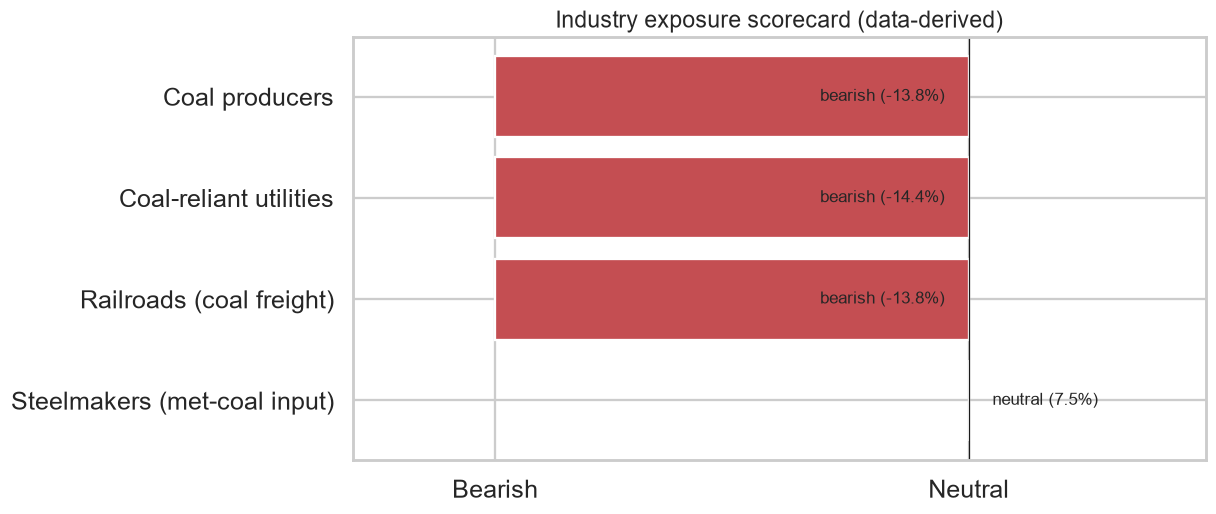

In [5]:
# Scorecard chart: stance as diverging colored bars
num = {'bearish': -1, 'neutral': 0, 'bullish': 1}
scorecard['num'] = scorecard['stance'].map(num)
fig, ax = plt.subplots(figsize=(10, 5))
colors = scorecard['num'].map({-1:'#c44e52', 0:'#999999', 1:'#55a868'})
ax.barh(scorecard['industry'][::-1], scorecard['num'][::-1], color=colors[::-1])
for i, (ind, st, val) in enumerate(zip(scorecard['industry'][::-1], scorecard['stance'][::-1], scorecard['value'][::-1])):
    ax.text(0.05 if scorecard.set_index('industry').loc[ind,'num'] >= 0 else -0.05,
            i, f'{st} ({val})', va='center',
            ha='left' if scorecard.set_index('industry').loc[ind,'num'] >= 0 else 'right', fontsize=11)
ax.set_xlim(-1.3, 0.5); ax.set_xticks([-1,0]); ax.set_xticklabels(['Bearish','Neutral'])
ax.set_title('Industry exposure scorecard (data-derived)', fontsize=15)
ax.axvline(0, color='k', lw=0.8)
savefig('08_industry_scorecard.png')

In [6]:
# Validation: every claim cites a metric/chart; no company names appear
assert scorecard['evidence'].str.endswith('.png').all(), 'each stance must cite a chart'
assert scorecard['key_metric'].notna().all()
assert 'stance' in scorecard.columns
print('Evidence table OK - every industry stance ties to a named metric + chart.')
print('No company names used (industry-level only).')

Evidence table OK - every industry stance ties to a named metric + chart.
No company names used (industry-level only).


**Takeaways**
- Each industry's stance is derived from a specific data metric: coal producers and railroads track national volume; coal-reliant utilities track electric-power coal; steelmakers track coke-plant (met) coal.
- The scorecard makes the differentiation explicit - where the data diverges across industries, the stances diverge too.